# Lab 6 — PyTorch + Transformers

## What you will learn
By the end of this lab, you will be able to:
1. Explain (in plain but academic language) what a *Transformer* is and why *pre-training + fine-tuning* works.
2. Fine-tune a **small** pre-trained Transformer for **text classification** using **PyTorch + Hugging Face**.
3. Evaluate the model with appropriate metrics and do **error analysis**.
4. Write a short **model card-style summary** (limitations, bias, safe use).

> **Important:** This is a **guided practice lab**. The **graded Assignment 3** (Lab Portfolio B) typically requires additional experiments and stronger justification. Do not copy-paste results from others.


## 0) Setup (Colab-friendly)

This notebook is designed to run on **Google Colab** with about **12 GB RAM**.

### Tips to avoid RAM/GPU issues
- Use a **small model** (default: `prajjwal1/bert-tiny`).
- Train on a **small subset** first (default: 5,000 examples).
- Keep `max_length=128`.
- If you get an out-of-memory error, reduce `batch_size`.

### (Optional) Enable GPU
In Colab: **Runtime → Change runtime type → GPU**.


In [1]:
# Install (Colab): run once
# If you run locally and already have these, you can skip.

!pip3 -q install -U transformers datasets evaluate accelerate scikit-learn

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
)
import evaluate
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print('Torch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

W1022 15:10:26.762000 99768 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Torch: 2.11.0
GPU available: False


In [3]:
# Reproducibility: fix random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Make results more stable (may be a bit slower)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 1) Concept warm-up: what changes from Week 6 to Week 7?

In Week 6, we used classical NLP ideas (bag-of-words, TF-IDF, simple embeddings).

In Week 7, we use **Transformers**, which learn contextual representations using **self-attention**.

### Minimal mental model (pipeline)
1. **Tokenizer** converts text → token IDs.
2. The Transformer converts token IDs → contextual vectors.
3. A small **classification head** maps vectors → label probabilities.


## 2) Dataset: SST-2 (sentiment)

We use **SST-2** (Stanford Sentiment Treebank, binary sentiment) from the GLUE benchmark.

- `label = 1` → positive
- `label = 0` → negative

We will train on a **subset** to keep the lab fast and memory-safe.


In [4]:
dataset = load_dataset('nyu-mll/glue', 'sst2')
dataset

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

In [5]:
# Peek at a few examples
pd.DataFrame(dataset['train'][:5])

,sentence,label,idx
0,hide new secretions from the parental units,0,0
1,"contains no wit , only labored gags",0,1
2,that loves its characters and communicates som...,1,2
3,remains utterly satisfied to remain the same t...,0,3
4,on the worst revenge-of-the-nerds clichés the ...,0,4


In [6]:
# Create small subsets (adjust sizes if you want)
TRAIN_SIZE = 5000
VAL_SIZE = 872 # Changed from 1000 to 872, as validation dataset has only 872 examples

train_ds = dataset['train'].shuffle(seed=SEED).select(range(TRAIN_SIZE))
val_ds = dataset['validation'].shuffle(seed=SEED).select(range(VAL_SIZE))

print('Train subset:', len(train_ds))
print('Val subset:', len(val_ds))

Train subset: 5000
Val subset: 872


## 3) Choose a model (small by default)

To keep this lab runnable on CPU/GPU, we start with a **tiny** BERT.

- Default: `prajjwal1/bert-tiny` (very small, fast)
- Optional upgrade: `distilbert-base-uncased` (better, larger)

You can switch the model by changing `MODEL_NAME`.


In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = 'distilbert-base-uncased'

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

print("Model and tokenizer loaded successfully:", MODEL_NAME)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model and tokenizer loaded successfully: distilbert-base-uncased


## 4) Tokenization

Tokenization converts text into **token IDs** the model understands.

Key parameter:
- `max_length`: longer sequences = more compute + more memory.

We use `max_length = 128` for safety.


In [14]:
MAX_LEN = 128

def tokenize_batch(batch):
    return tokenizer(batch['sentence'], truncation=True, max_length=MAX_LEN)

train_tok = train_ds.map(tokenize_batch, batched=True)
val_tok = val_ds.map(tokenize_batch, batched=True)

# Remove raw text column to save memory during training
train_tok = train_tok.remove_columns(['sentence'])
val_tok = val_tok.remove_columns(['sentence'])

# Trainer expects 'label' field
train_tok = train_tok.rename_column('label', 'labels')
val_tok = val_tok.rename_column('label', 'labels')

train_tok.set_format('torch')
val_tok.set_format('torch')

train_tok[0]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

{'labels': tensor(1),
 'idx': tensor(32326),
 'input_ids': tensor([  101, 12555,  1010, 11951,  1999, 22092,  2066,  2137, 11345,  1998,
          2757,  1011,  2006,  1999,  2602,  1010,   102]),
 'token_type_ids': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])}

In [15]:
# Show what tokenization looks like for one sentence
example = dataset['train'][0]['sentence']
enc = tokenizer(example, truncation=True, max_length=MAX_LEN)
print('Text:', example)
print('Token IDs (first 20):', enc['input_ids'][:20])
print('Tokens (first 20):', tokenizer.convert_ids_to_tokens(enc['input_ids'][:20]))

Text: hide new secretions from the parental units 
Token IDs (first 20): [101, 5342, 2047, 3595, 8496, 2013, 1996, 18643, 3197, 102]
Tokens (first 20): ['[CLS]', 'hide', 'new', 'secret', '##ions', 'from', 'the', 'parental', 'units', '[SEP]']


## 5) Fine-tuning (Trainer API)

We fine-tune the model on our task.

### Memory-safe defaults
- Small batch size
- 1 epoch
- Short max sequence length

If you see **CUDA OOM**, reduce `BATCH_SIZE` (e.g., 16 → 8 → 4).


In [18]:
# Choose batch size based on hardware
BATCH_SIZE = 16 if torch.cuda.is_available() else 8

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

accuracy = evaluate.load('accuracy')
f1 = evaluate.load('f1')


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy.compute(predictions=preds, references=labels)['accuracy'],
        'f1': f1.compute(predictions=preds, references=labels, average='binary')['f1'],
    }

args = TrainingArguments(
    output_dir='lab3_transformer_sentiment',
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy='epoch', # Changed from evaluation_strategy to eval_strategy
    save_strategy='no',
    logging_steps=50,
    fp16=bool(torch.cuda.is_available()),
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.318723,0.333385,0.875000,0.875713


TrainOutput(global_step=625, training_loss=0.38338565521240237, metrics={'train_runtime': 84.9842, 'train_samples_per_second': 58.834, 'train_steps_per_second': 7.354, 'total_flos': 38239612346400.0, 'train_loss': 0.38338565521240237, 'epoch': 1.0})

In [19]:
# Final evaluation on the validation subset
metrics = trainer.evaluate()
metrics

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.318723,0.333385,1,0.875000,0.875713


{'eval_loss': 0.33338484168052673,
 'eval_accuracy': 0.875,
 'eval_f1': 0.8757126567844926}

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


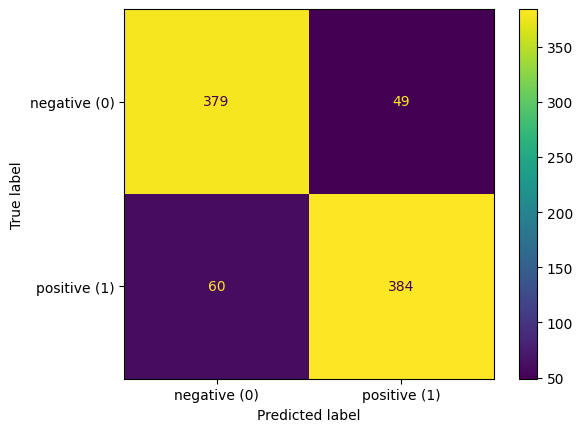

In [20]:
# Predictions for deeper analysis
pred_output = trainer.predict(val_tok)
logits = pred_output.predictions
labels = pred_output.label_ids
preds = np.argmax(logits, axis=-1)

# Confusion matrix
cm = confusion_matrix(labels, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=['negative (0)', 'positive (1)'])
disp.plot(values_format='d')
plt.show()

## 6) Error analysis (what does the model get wrong?)

Accuracy alone is not enough. In business settings, you also want:
- **What kinds of texts fail?** (sarcasm, negation, slang)
- **Do failures create a risk?** (wrong moderation decisions, wrong recommendations)

We will inspect a few misclassified examples.


In [21]:
# Reattach text for analysis (we kept val_ds with 'sentence')
val_texts = val_ds['sentence']

mis_idx = np.where(preds != labels)[0]
print('Misclassified:', len(mis_idx), 'out of', len(labels))

# Show up to 10 mistakes
for i in mis_idx[:10]:
    print('---')
    print('Text:', val_texts[i])
    print('True label:', int(labels[i]), '| Predicted:', int(preds[i]))

Misclassified: 109 out of 872
---
Text: the film tunes into a grief that could lead a man across centuries . 
True label: 1 | Predicted: 0
---
Text: you 'll gasp appalled and laugh outraged and possibly , watching the spectacle of a promising young lad treading desperately in a nasty sea , shed an errant tear . 
True label: 1 | Predicted: 0
---
Text: sam mendes has become valedictorian at the school for soft landings and easy ways out . 
True label: 0 | Predicted: 1
---
Text: the last 20 minutes are somewhat redeeming , but most of the movie is the same teenage american road-trip drek we 've seen before - only this time you have to read the fart jokes 
True label: 0 | Predicted: 1
---
Text: not far beneath the surface , this reconfigured tale asks disturbing questions about those things we expect from military epics . 
True label: 1 | Predicted: 0
---
Text: no screen fantasy-adventure in recent memory has the showmanship of clones ' last 45 minutes . 
True label: 1 | Predicted: 0
---
T

## 7) Quick robustness check (stress test)

A simple (but informative) test is to slightly modify a sentence and see if the prediction flips.
This helps reveal **fragility**.

Try changing punctuation, adding "not", or rephrasing.


In [22]:
def predict_sentiment(texts):
    model.eval()
    inputs = tokenizer(texts, truncation=True, max_length=MAX_LEN, return_tensors='pt', padding=True)
    inputs = {k: v.to(model.device) for k,v in inputs.items()}
    with torch.no_grad():
        out = model(**inputs)
        probs = torch.softmax(out.logits, dim=-1).cpu().numpy()
    pred = probs.argmax(axis=-1)
    return pred, probs

examples = [
    "This movie is good.",
    "This movie is good!!!",
    "This movie is not good.",
    "I expected a masterpiece, but it was disappointing.",
]

pred, probs = predict_sentiment(examples)
for t,p,pr in zip(examples, pred, probs):
    print(f"{t} -> pred={int(p)} (Pneg={pr[0]:.3f}, Ppos={pr[1]:.3f})")

This movie is good. -> pred=1 (Pneg=0.010, Ppos=0.990)
This movie is good!!! -> pred=1 (Pneg=0.012, Ppos=0.988)
This movie is not good. -> pred=0 (Pneg=0.978, Ppos=0.022)
I expected a masterpiece, but it was disappointing. -> pred=0 (Pneg=0.968, Ppos=0.032)


## 8) Responsible AI notes (business risk controls)

In real systems, language models can fail in ways that matter:
- **Bias / unfairness:** sentiment may vary across dialects or cultural expressions.
- **Spurious cues:** the model may rely on irrelevant patterns.
- **Overconfidence:** high probability does not guarantee correctness.

### Your task (write 3–5 bullets)
1. What are two realistic failure cases for your domain?
2. What simple mitigations could a company apply?
   - human-in-the-loop review
   - thresholding (only act on high-confidence)
   - monitoring and periodic evaluation


## 9) Mini model card (practice template)

Fill this in **briefly**. In a graded submission, you would write more carefully.

### Model card
- **Model name:** *(e.g., prajjwal1/bert-tiny fine-tuned on SST-2 subset)*
- **Intended use:**
  - *(What is the model used for? Who is the user?)*
- **Not intended use:**
  - *(What should it NOT be used for?)*
- **Data:**
  - *(Dataset name + a one-sentence description)*
- **Metrics:**
  - *(Accuracy, F1, and a short interpretation)*
- **Key limitations:**
  - *(At least 2)*
- **Bias & fairness considerations:**
  - *(At least 2)*
- **Safe-use recommendations:**
  - *(At least 3)*

> If you want, you can export this section as a PDF for submission.


## 10) Save your fine-tuned model (optional)

Saving lets you reuse the model later without retraining.


In [23]:
SAVE_DIR = 'lab3_saved_model'
os.makedirs(SAVE_DIR, exist_ok=True)

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print('Saved to:', SAVE_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: lab3_saved_model


### Load the saved model and run inference (optional)


In [24]:
from transformers import pipeline

clf = pipeline('text-classification', model=SAVE_DIR, tokenizer=SAVE_DIR, device=0 if torch.cuda.is_available() else -1)
clf(["I really liked this film.", "This was boring and too long."])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'LABEL_1', 'score': 0.9824861288070679},
 {'label': 'LABEL_0', 'score': 0.983834981918335}]

## 11) Optional extensions (do only if you have time)

1. **Upgrade model**: switch to `distilbert-base-uncased` and compare metrics.
2. **Freeze layers**: freeze the Transformer body and train only the classification head. Does performance change?
3. **Longer context**: try `max_length=256` (watch memory!).
4. **Error taxonomy**: label 20 errors into categories (negation, sarcasm, ambiguity, rare words).
5. **Domain shift**: test on your own sentences from a business domain (e.g., product reviews in your language).

> For a graded assignment, you would typically choose 2–3 extensions and justify them.


## 12) Memory cleanup (if you ran out of RAM)

If Colab becomes slow or crashes:
- **Runtime → Restart runtime**
- Lower `TRAIN_SIZE`, `BATCH_SIZE`, or `MAX_LEN`
- Use the tiny model

You can also manually clear GPU memory:


In [25]:
# Optional cleanup
import gc

del trainer

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('Cleaned up!')

Cleaned up!
